# $\zeta(2)+\zeta(3)$: historical construction and new trajectory

Exact rational approximants, sampled up to index 500.
$\delta_N=-1-\log|\alpha-p_N/q_N|/\log q_N$ and
$D_N=-\log_{10}|\alpha-p_N/q_N|$, with reduced $p_N/q_N$.
Published results and finite-depth measurements are distinct; source-index exceptions are stated below.

In [ ]:
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 python-flint==0.9.0 matplotlib==3.11.2

## Setup

In [1]:
import sys
import matplotlib.pyplot as plt
import sympy as sp
from flint import arb, ctx
from IPython.display import Markdown, display
from ramanujantools.cmf.pfq import pFq
from cmfs import (
    zeta23_search_seeds, zudilin_zeta23_seeds, zudilin_zeta_sum_readout,
)

sys.set_int_max_str_digits(0)
DEPTHS = list(range(10, 501, 10))
results, accuracy = {}, {}
x0, x1, x2, x3, y0, y1, y2 = sp.symbols('x0 x1 x2 x3 y0 y1 y2')
target = lambda: arb(2).zeta()+arb(3).zeta()


def measure(approximant, target):
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(4 * q.bit_length() + 256):
        error = abs(target() - arb(p) / q)
        assert error > 0 and q > 1
        value = -1 - error.log() / arb(q).log()
        assert value.is_finite() and value.rad() < arb("1e-18")
        return float(value.mid()), float((-error.log() / arb(10).log()).mid())

## 1. Zudilin (2002): sum of simultaneous approximants

[Primary paper](https://arxiv.org/pdf/math/0206178).

**CMF:** ${}_4F_3(1)$, rank 3, with 7 parameter axes. All hypergeometric axes are retained.
**Start at source N=2:** (3,3,3,3;6,6,6). **Direction:** (1,1,1,1;2,2,2). **Walk depth:** N-2; the diagnostic at source N=500 uses exactly 498 steps.

In [5]:
pair = (2, 3)
cmf = pFq(4, 3, 1)
axes = sp.symbols('x0:4') + sp.symbols('y0:3')
start = dict(zip(axes, [3] * 4 + [6] * 3))
trajectory = dict(zip(axes, [1] * 4 + [2] * 3))
seeds = zudilin_zeta23_seeds()
walks = list(cmf.walk(trajectory, [N - 2 for N in DEPTHS], start))
approximants = [zudilin_zeta_sum_readout(W, N, seeds, pair) for N, W in zip(DEPTHS, walks)]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Zudilin (2002), sum'] = (DEPTHS, deltas)
accuracy['Zudilin (2002), sum'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: -0.153718300028


## 2. Dauguet–Zudilin (2014)

[Paper](https://doi.org/10.1016/j.jnt.2014.06.007).

**CMF:** ${}_4F_3(1)$ · **Start:** $(1,1,1,0;1,1,1)$ ·
**Direction:** $(10,9,8,-5;3,2,1)$. We use the direct walk and the
extraction $p_N/q_N=s_1/s_0$.

The simultaneous bound concerns constrained linear forms, not the ordinary irrationality measure.

In [7]:
cmf = pFq(4, 3, 1)
start = {x0: 1, x1: 1, x2: 1, x3: 0, y0: 1, y1: 1, y2: 1}
trajectory = {x0: 10, x1: 9, x2: 8, x3: -5, y0: 3, y1: 2, y2: 1}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [W[1, 0] / W[0, 0] for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Dauguet–Zudilin (2014)'] = (DEPTHS, deltas)
accuracy['Dauguet–Zudilin (2014)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: -0.098711683941


## 3. New ${}_4F_3(1)$ trajectory

[Local manuscript](../overleaf_paper/New_directions_in_irrationality/main.tex).

**CMF:** ${}_4F_3(1)$ · **Start:** $(7,8,6,9;2,3,16)$ ·
**Direction:** $(11,13,15,16;2,4,30)$. We use the direct walk. With
$c_j=s_j/s_0$, the extraction is $p_N/q_N=N_{2,3}/D_{2,3}$, where
$$\begin{aligned}
N_{2,3}&=320242182383092497c_1-5523372274576928103c_2-18266336406752995,\\
D_{2,3}&=112484439099648000c_1-194007368929651500c_2-6416014872960000.
\end{aligned}$$

In [9]:
cmf = pFq(4, 3, 1)
start = {x0: 7, x1: 8, x2: 6, x3: 9, y0: 2, y1: 3, y2: 16}
trajectory = {x0: 11, x1: 13, x2: 15, x3: 16, y0: 2, y1: 4, y2: 30}
P, Q = zeta23_search_seeds()
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(P * W)[0] / (Q * W)[0] for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['New ${}_4F_3(1)$ trajectory'] = (DEPTHS, deltas)
accuracy['New ${}_4F_3(1)$ trajectory'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.000586285504


## Comparison

Only completed runs are shown. N follows each example’s stated index convention.

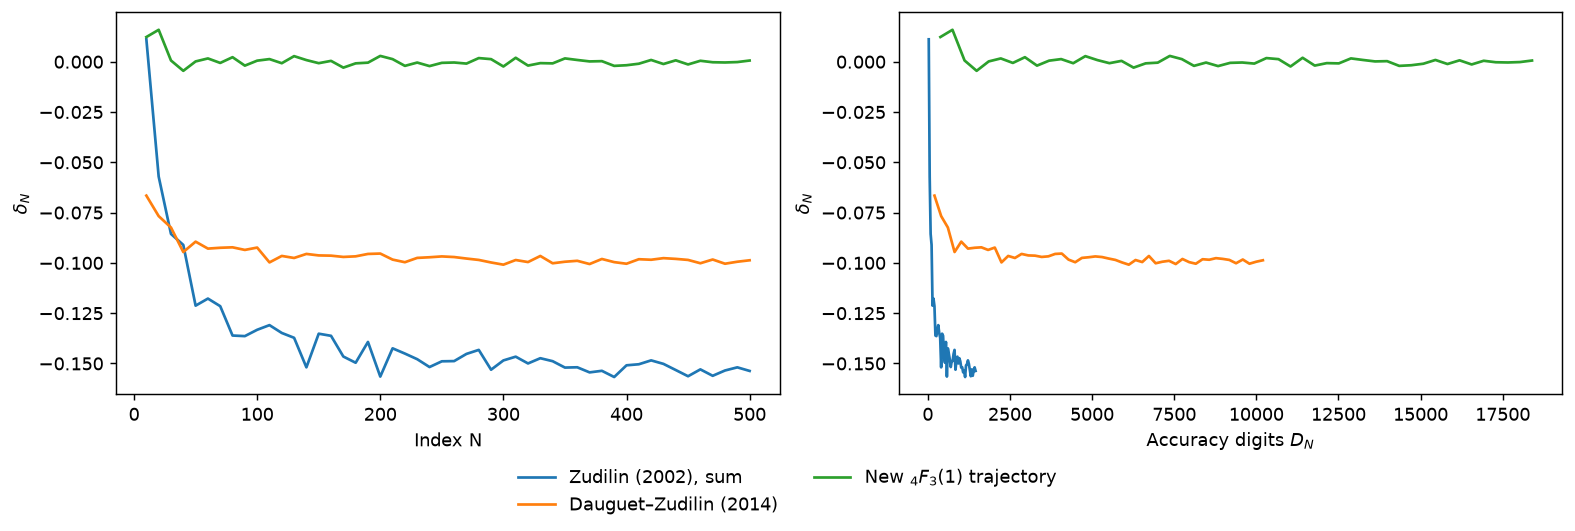

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, (depths, deltas) in results.items():
    axes[0].plot(depths, deltas, label=name)
    axes[1].plot(accuracy[name], deltas)
axes[0].set(xlabel="Index N", ylabel=r"$\delta_N$")
axes[1].set(xlabel=r"Accuracy digits $D_N$", ylabel=r"$\delta_N$")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=2, frameon=False)
plt.show()

## Historical overview

Only implemented CMF recoveries are listed. The measured column states the actual final index.

In [13]:
bounds = {
    'Zudilin (2002), sum': 'Component convergence estimates; no measure bound',
    'Dauguet–Zudilin (2014)': 'Simultaneous approximation construction',
    'New ${}_4F_3(1)$ trajectory': 'Experimental approximation trajectory',
}
rows = ["| Construction | Published result | Measured delta |", "|:--|:--|:--|"]
for name, bound in bounds.items():
    if name in results:
        depths, deltas = results[name]
        value = f"{deltas[-1]:.12f} (N = {depths[-1]})"
    else:
        value = "Not computed"
    rows.append(f"| {name} | {bound} | {value} |")
display(Markdown("\n".join(rows)))

| Construction | Published result | Measured delta |
|:--|:--|:--|
| Zudilin (2002), sum | Component convergence estimates; no measure bound | -0.153718300028 (N = 500) |
| Dauguet–Zudilin (2014) | Simultaneous approximation construction | -0.098711683941 (N = 500) |
| New ${}_4F_3(1)$ trajectory | Experimental approximation trajectory | 0.000586285504 (N = 500) |